# Diagnose data-dependent SW tuning: matched A/B/C experiment

This notebook reproduces the **size DGP** in your existing `sw_table_abc` notebook: independent \(Y\sim N(\beta,25)\), \(X\sim N(\beta,1)\), with model 1 fitting the mean of \(Y\) and fixing the mean of \(X\) at zero, and model 2 doing the reverse. Both models have the same population expected log likelihood.

For **each identical simulated dataset**, calculate the Schennach–Wilhelm statistic under:
- **A:** epsilon estimated from that dataset;
- **B:** epsilon fixed at the median of the 700 estimated epsilons;
- **C:** epsilon randomly reassigned from a *different* Monte Carlo replication.

The permutation in C preserves the empirical epsilon distribution, but removes its same-dataset association with the numerator and denominator. **This is a diagnostic, not a proposed new test.** The experiment uses the **normal-reference SW test**, not the bootstrap; bootstrap critical values would require a different, more expensive experiment.

The notebook is self-contained (no changes to your existing module or notebook), and parallelizes **across datasets** using `joblib`/`loky`. It uses the analytical Gaussian likelihood, scores and Hessians equivalent to your `JointNormal1`/`JointNormal2` definitions, avoiding repeated numerical differentiation. The tuning formula and its floor match your latest uploaded module (including the `sigma2` floor of **0.01**).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from joblib import Parallel, delayed, parallel_backend
from IPython.display import display

# Experiment settings. Your existing size notebook uses nobs=200.
BETA = 0.6923076923076923
NOBS = 200                    # even, as in your SW implementation
NSIMS = 700
ALPHA = 0.05
SEED = 20261112
N_JOBS = 8                    # Windows-safe worker limit
N_PERMUTATIONS = 200         # cheap: reuses all datasets; no model re-fitting

# Match the CURRENT tuning implementation in your uploaded .py file.
SIGMA2_FLOOR = 0.01
EPSILON_AT_REFERENCE = 0.05
REFERENCE_N = 500
MAX_EPSILON = np.inf
BIAS_CORRECT = False          # current tuned SW normal test uses biascorrect=False

assert NOBS % 2 == 0
print(f"beta={BETA:.4f}, n={NOBS}, replications={NSIMS}, workers={N_JOBS}")

beta=0.6923, n=200, replications=700, workers=8


## 1. Exact Gaussian likelihood components

Your models have per-observation likelihoods
\(\ell_{1i}=-\log(2\pi)-[(Y_i-\bar Y)^2+X_i^2]/2\) and
\(\ell_{2i}=-\log(2\pi)-[Y_i^2+(X_i-\bar X)^2]/2\).
Scores are \(Y_i-\bar Y\) and \(X_i-\bar X\); both total Hessians equal \(-n\).

We store only the components needed to evaluate **any epsilon** without refitting:
\(D=\sum_i(\ell_{1i}-\ell_{2i})\),
\(S=\sum_{i\ \mathrm{even}}\ell_{1i}-\sum_{i\ \mathrm{odd}}\ell_{2i}\),
and the three sample variances. This matches your `sw_test_stat` implementation.

In [2]:
def gaussian_components(seed, beta=BETA, n=NOBS):
    rng = np.random.default_rng(int(seed))
    # Same DGP as gen_data(): independent N(beta,25) and N(beta,1).
    y = rng.normal(beta, 5.0, n)
    x = rng.normal(beta, 1.0, n)
    mu1, mu2 = y.mean(), x.mean()
    const = -np.log(2 * np.pi)
    ll1 = const - 0.5 * ((y - mu1)**2 + x**2)
    ll2 = const - 0.5 * (y**2 + (x - mu2)**2)
    score1, score2 = y - mu1, x - mu2

    # _estimate_HV: H = -hess_total/n = 1, V = mean(score**2).
    tr_max = max(np.mean(score1**2), np.mean(score2**2))
    sigma2_raw = float(np.var(ll1 - ll2))
    sigma2_tuning = max(sigma2_raw, SIGMA2_FLOOR)
    sigmaA2_tuning = float(np.var(ll1))
    sigmaB2_tuning = float(np.var(ll2))
    sigma = np.sqrt(sigma2_tuning)

    # compute_optimal_epsilon, copied algebraically from your uploaded version.
    z = norm.ppf(ALPHA / 2)
    delta = sigma / 2 * (z - np.sqrt(4 + z**2))
    C_PL = (norm.pdf(z - delta/sigma) * delta
            * (sigma2_tuning - 2*(sigmaA2_tuning + sigmaB2_tuning))
            / (4*sigma**3))
    C_SD = (2 * norm.pdf(z) * tr_max
            / np.sqrt(max((sigmaA2_tuning + sigmaB2_tuning)/2, 1e-12)))
    if not (np.isfinite(C_PL) and C_PL > 0 and
            np.isfinite(C_SD) and C_SD > 0):
        raise ValueError(f"Invalid tuning constants: C_PL={C_PL}, C_SD={C_SD}")
    rate = n**(-1/6) * np.log(np.log(n))**(1/3)
    reference_rate = REFERENCE_N**(-1/6) * np.log(np.log(REFERENCE_N))**(1/3)
    epsilon_raw = (C_SD/C_PL)**(1/3) * rate
    epsilon_floor = EPSILON_AT_REFERENCE * rate / reference_rate
    epsilon = float(np.clip(epsilon_raw, epsilon_floor, MAX_EPSILON))

    return {
        "D": float(np.sum(ll1-ll2)),
        "S": float(np.sum(ll1[::2]) - np.sum(ll2[1::2])),
        "omega2": sigma2_raw,
        "omegaA2": float(np.var(ll1[::2])),
        "omegaB2": float(np.var(ll2[1::2])),
        "sigma2_tuning": sigma2_tuning,
        "epsilon": epsilon,
        "epsilon_raw": epsilon_raw,
        "floor_binding": epsilon_raw < epsilon_floor,
        "C_PL": C_PL, "C_SD": C_SD,
        "bias_term": 0.0,  # BIAS_CORRECT=False; no eigenvalue calculation needed.
    }


def sw_t_from_components(data, eps):
    eps = np.asarray(eps, dtype=float)
    numerator = data["D"] + eps * data["S"]
    variance = ((1 + eps) * data["omega2"]
                + eps**2 / 2 * (data["omegaA2"] + data["omegaB2"]))
    return numerator / np.sqrt(NOBS * variance)


def decision(t, alpha=ALPHA):
    cutoff = norm.ppf(1 - alpha/2)
    return np.where(t >= cutoff, 1, np.where(t <= -cutoff, 2, 0))

## 2. Generate 700 datasets in parallel

The only expensive step is generating and fitting each dataset. All three epsilon assignments reuse the same stored components. The random streams are independent and reproducible across workers.

In [3]:
seeds = [int(s.generate_state(1)[0])
         for s in np.random.SeedSequence(SEED).spawn(NSIMS)]

if N_JOBS == 1:
    records = [gaussian_components(s) for s in seeds]
else:
    with parallel_backend("loky", inner_max_num_threads=1):
        records = Parallel(n_jobs=N_JOBS, batch_size="auto", verbose=5)(
            delayed(gaussian_components)(s) for s in seeds
        )

df = pd.DataFrame(records)
median_eps = float(df["epsilon"].median())
print(f"Median tuned epsilon: {median_eps:.4f}; "
      f"floor binds: {df['floor_binding'].mean():.1%}")
display(df[["epsilon", "epsilon_raw", "sigma2_tuning", "omega2",
            "C_PL", "C_SD"]].describe(percentiles=[.1,.5,.9]).round(3))

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:    2.6s
[Parallel(n_jobs=8)]: Done  81 tasks      | elapsed:    2.7s


Median tuned epsilon: 0.0969; floor binds: 11.0%


[Parallel(n_jobs=8)]: Done 604 tasks      | elapsed:    2.8s
[Parallel(n_jobs=8)]: Done 700 out of 700 | elapsed:    2.9s finished


,epsilon,epsilon_raw,sigma2_tuning,omega2,C_PL,C_SD
count,700.000,700.000,700.000,700.000,700.000,700.000
mean,0.099,0.098,16.187,16.187,50.900,0.166
std,0.029,0.031,13.726,13.726,87.640,0.013
min,0.057,0.030,0.438,0.438,2.722,0.126
10%,0.057,0.054,2.146,2.146,7.445,0.150
50%,0.097,0.097,12.658,12.658,21.152,0.166
90%,0.139,0.139,34.965,34.965,118.644,0.184
max,0.204,0.204,99.570,99.570,630.125,0.203


## 3. A, B and C on identical datasets

**A** uses own epsilon. **B** fixes epsilon at the observed median. **C** permutes epsilon *without replacement* across replications. We repeat the permutation 200 times to quantify permutation noise. All rejection rates are normal-reference two-sided tests at 5%.

To avoid the rare chance of a dataset retaining its own epsilon, C uses a random cyclic shift of a random permutation; the reassignment is independent of each dataset's values, though an occasional self-match is possible and negligible at 700 replications.

In [4]:
arrays = {key: df[key].to_numpy(dtype=float)
          for key in ["D", "S", "omega2", "omegaA2", "omegaB2"]}
eps = df["epsilon"].to_numpy()
t_A = sw_t_from_components(arrays, eps)
t_B = sw_t_from_components(arrays, np.full(NSIMS, median_eps))

rng_perm = np.random.default_rng(SEED + 1)
t_C_all = np.empty((N_PERMUTATIONS, NSIMS))
for j in range(N_PERMUTATIONS):
    # Derangement: each dataset receives another dataset's epsilon.
    order = rng_perm.permutation(NSIMS)
    # Rotate any fixed points until there are none.
    while np.any(order == np.arange(NSIMS)):
        order = rng_perm.permutation(NSIMS)
    t_C_all[j] = sw_t_from_components(arrays, eps[order])

def summarize(t):
    d = decision(t)
    return {
        "Reject %": 100 * np.mean(d != 0),
        "Model 1 %": 100 * np.mean(d == 1),
        "Model 2 %": 100 * np.mean(d == 2),
        "Mean t": np.mean(t),
        "SD t": np.std(t, ddof=1),
    }

summary = pd.DataFrame({
    "A: own tuned": summarize(t_A),
    "B: fixed median": summarize(t_B),
    "C: permuted (avg)": {
        key: np.mean([summarize(t_C_all[j])[key]
                      for j in range(N_PERMUTATIONS)])
        for key in summarize(t_A)
    }
}).T
display(summary.round(3))
print("C permutation rejection-rate range (5th–95th percentile):",
      np.round(np.percentile(100*np.mean(decision(t_C_all)!=0,axis=1),
                             [5,95]), 2))

,Reject %,Model 1 %,Model 2 %,Mean t,SD t
A: own tuned,9.429,0.429,9.000,-0.166,1.183
B: fixed median,6.429,0.429,6.000,-0.077,1.065
C: permuted (avg),6.854,0.436,6.418,-0.080,1.078


C permutation rejection-rate range (5th–95th percentile): [6.14 7.57]


## 4. Where do the rejections occur?

Quartiles are defined **once** by the original dataset's raw \(\hat\sigma^2\) (the variance used in the SW denominator), and held fixed across A/B/C. This avoids reclassifying observations when epsilon changes.

In [5]:
quartile = pd.qcut(df["omega2"].rank(method="first"), 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
rows = []
for q in ["Q1 low", "Q2", "Q3", "Q4 high"]:
    mask = np.asarray(quartile == q)
    row = {
        "Quartile": q,
        "N": int(mask.sum()),
        "Median raw sigma2": float(np.median(arrays["omega2"][mask])),
        "Median epsilon": float(np.median(eps[mask])),
        "A reject %": 100*np.mean(decision(t_A[mask]) != 0),
        "B reject %": 100*np.mean(decision(t_B[mask]) != 0),
        "C reject %": 100*np.mean(decision(t_C_all[:,mask]) != 0),
        "A mean t": float(t_A[mask].mean()),
        "A SD t": float(t_A[mask].std(ddof=1)),
    }
    rows.append(row)
quartile_table = pd.DataFrame(rows).set_index("Quartile")
display(quartile_table.round(3))

,N,Median raw sigma2,Median epsilon,A reject %,B reject %,C reject %,A mean t,A SD t
Quartile,,,,,,,,
Q1 low,175,2.751,0.060,36.000,24.000,25.283,-1.625,1.083
Q2,175,9.192,0.088,0.000,0.000,0.389,-0.314,0.569
Q3,175,16.732,0.107,0.000,0.000,0.000,0.322,0.467
Q4 high,175,31.818,0.133,1.714,1.714,1.743,0.952,0.494


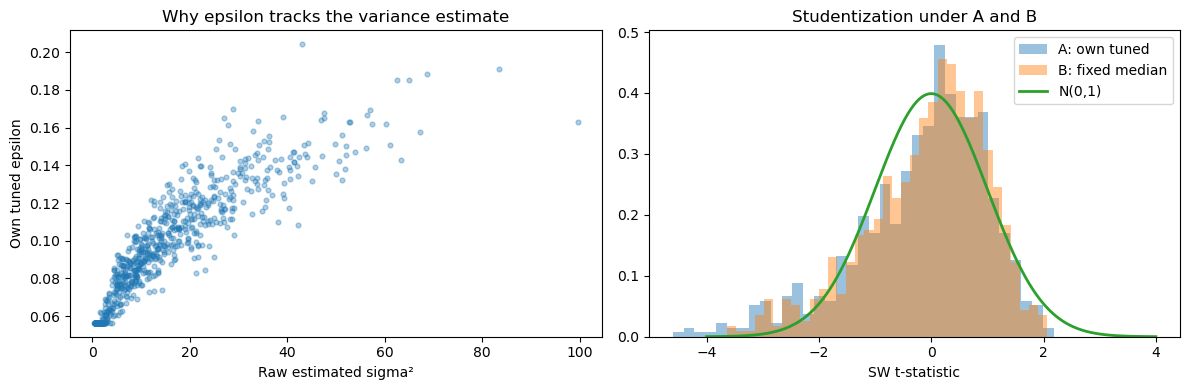

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(df["omega2"], eps, alpha=0.35, s=12)
axes[0].set(xlabel="Raw estimated sigma²", ylabel="Own tuned epsilon",
            title="Why epsilon tracks the variance estimate")
axes[1].hist(t_A, bins=35, density=True, alpha=.45, label="A: own tuned")
axes[1].hist(t_B, bins=35, density=True, alpha=.45, label="B: fixed median")
grid = np.linspace(-4,4,300)
axes[1].plot(grid, norm.pdf(grid), label="N(0,1)", linewidth=2)
axes[1].set(xlabel="SW t-statistic", title="Studentization under A and B")
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Interpretation

- **A oversized, B and C well-sized:** evidence that *same-dataset dependence* of epsilon and the statistic is important.
- **A and C oversized, B well-sized:** evidence that the *distribution of epsilon values* matters even when epsilon is independently assigned.
- **A, B and C oversized:** look beyond the tuning dependence, including small-epsilon behavior and finite-sample studentization.
- **A well-sized:** check that `BETA`, `NOBS`, the tuning floor, and the null DGP match the problematic run.

**Important limitation:** The test is normal-reference SW, **not the singleton bootstrap**. Your earlier notebook prints bootstrap decisions separately, and they can have different size behavior. If the bootstrap is the principal concern, the same A/B/C design should be repeated with its bootstrap critical values.

The `sigma2_tuning` floor affects epsilon **only**. The statistic always uses the raw `omega2`, exactly as in your current code.

## 6. Fixed-epsilon sensitivity (same 700 datasets)

No additional simulations or fitting. This isolates the finite-sample impact of the *level* of epsilon. The additional diagnostic plots numerator and denominator components to identify whether the change comes from regularization of the denominator or the numerator.

,epsilon,Reject %,Model 1 %,Model 2 %,Mean t,SD t
0,0.025,10.429,0.286,10.143,-0.240,1.306
1,0.050,9.429,0.286,9.143,-0.177,1.191
2,0.075,7.714,0.429,7.286,-0.118,1.109
3,0.100,6.429,0.429,6.000,-0.072,1.060
4,0.150,4.714,0.429,4.286,-0.008,1.019
5,0.200,4.571,0.857,3.714,0.028,1.009
6,0.300,4.429,1.286,3.143,0.062,1.014
7,0.500,4.429,1.714,2.714,0.074,1.029
8,0.750,4.571,1.857,2.714,0.069,1.037
9,1.000,4.571,1.714,2.857,0.062,1.041


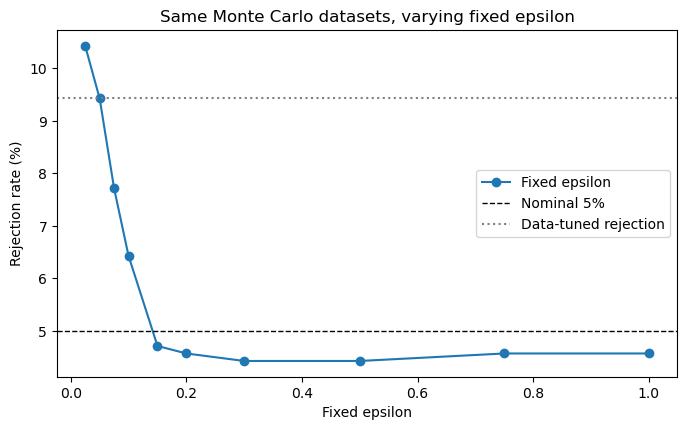

In [7]:
EPSILON_GRID = np.array([0.025, 0.05, 0.075, 0.10, 0.15, 0.20, 0.30, 0.50, 0.75, 1.0])
fixed_t = np.stack([sw_t_from_components(arrays, e) for e in EPSILON_GRID])
fixed_summary = pd.DataFrame([{"epsilon": float(e), **summarize(t)}
                              for e, t in zip(EPSILON_GRID, fixed_t)])
display(fixed_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(fixed_summary["epsilon"], fixed_summary["Reject %"], "o-", label="Fixed epsilon")
ax.axhline(5, color="black", linestyle="--", linewidth=1, label="Nominal 5%")
ax.axhline(summary.loc["A: own tuned", "Reject %"], color="gray", linestyle=":", label="Data-tuned rejection")
ax.set(xlabel="Fixed epsilon", ylabel="Rejection rate (%)", title="Same Monte Carlo datasets, varying fixed epsilon")
ax.legend()
plt.show()

## 7. Mechanism diagnostic

The numerator is `D + epsilon*S` and the denominator squared is `n*((1+epsilon)*omega2 + epsilon**2/2*(omegaA2+omegaB2))`. Compare the empirical dispersion of the numerator across Monte Carlo replications with the average estimated denominator, and inspect rejection rates in the bottom quartile of the raw variance. These are diagnostics, not a proof of the source of size distortion.

In [8]:
q1 = arrays["omega2"] <= np.quantile(arrays["omega2"], .25)
mechanism = []
for e, t in zip(EPSILON_GRID, fixed_t):
    numer = arrays["D"] + e * arrays["S"]
    varhat = ((1+e)*arrays["omega2"] + e**2/2*(arrays["omegaA2"]+arrays["omegaB2"]))
    mechanism.append({
        "epsilon": e,
        "Numerator SD / sqrt(n)": np.std(numer, ddof=1)/np.sqrt(NOBS),
        "sqrt(mean estimated variance)": np.sqrt(np.mean(varhat)),
        "Mean t": np.mean(t),
        "SD t": np.std(t, ddof=1),
        "Q1 reject %": 100*np.mean(decision(t[q1]) != 0),
        "Other quartiles reject %": 100*np.mean(decision(t[~q1]) != 0),
    })
display(pd.DataFrame(mechanism).round(3))

,epsilon,Numerator SD / sqrt(n),sqrt(mean estimated variance),Mean t,SD t,Q1 reject %,Other quartiles reject %
0,0.025,3.963,4.098,-0.240,1.306,40.571,0.381
1,0.050,4.092,4.217,-0.177,1.191,36.571,0.381
2,0.075,4.267,4.379,-0.118,1.109,29.143,0.571
3,0.100,4.483,4.579,-0.072,1.060,24.000,0.571
4,0.150,5.017,5.072,-0.008,1.019,16.000,0.952
5,0.200,5.653,5.662,0.028,1.009,13.714,1.524
6,0.300,7.117,7.033,0.062,1.014,10.286,2.476
7,0.500,10.422,10.160,0.074,1.029,6.857,3.619
8,0.750,14.818,14.352,0.069,1.037,6.286,4.000
9,1.000,19.323,18.660,0.062,1.041,5.714,4.190
